# m04 - Spatial-Context Features and Coarse Training Rows

Suitability can depend on the landscape around a cell as well as on the cell itself, so the point value of a feature
at one 1 km cell is not necessarily the right support. Two ways to give the model spatial context:

1. **Focal means**: average every input over k x k neighbourhoods on the 1 km grid (k = 3 ... 41 km).
2. **Pixel means**: average every input over the ~9 km GAEZ pixel the cell belongs to.

Then the opposite route: **train on ~9 km pixel averages** (one row per pixel of the GAEZ 5 arc-minute grid, inputs and
the 1 km target averaged) and compare it with the cell-level models after aggregating their predictions to the same
pixels. Inputs are smoothed, never targets, so none of this leaks labels; all scores use pixel-grouped CV (5 folds x 2
repeats) unless noted.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
base = E.feature_columns()
SIZES = (3, 5, 9, 15, 25, 41)
dfc = E.add_focal_features(df, base, SIZES)
dfc = E.add_pixel_mean_features(dfc, base)

def focal(*sizes):
    return [f"{c}__f{k}" for k in sizes for c in base]
pixmean = [f"{c}__pix" for c in base]

feature_sets = {
    "point (base)": base,
    "+ focal 3": base + focal(3),
    "+ focal 9": base + focal(9),
    "+ focal 3, 9, 25": base + focal(3, 9, 25),
    "+ all focal": base + focal(*SIZES),
    "focal 9 only": focal(9),
    "pixel mean only": pixmean,
    "base + pixel mean": base + pixmean,
}
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)
{k: len(v) for k, v in feature_sets.items()}

{'point (base)': 14,
 '+ focal 3': 28,
 '+ focal 9': 28,
 '+ focal 3, 9, 25': 56,
 '+ all focal': 98,
 'focal 9 only': 14,
 'pixel mean only': 14,
 'base + pixel mean': 28}

## 1. Context features, cell-level models

In [3]:
MODELS = ["ridge", "hgb"]
parts, keep = [], {}
for name, cols in feature_sets.items():
    r, oof = E.run_grid(dfc, targets, MODELS, ["pixel"], columns=cols, n_repeats=2, keep_oof=True, verbose=False)
    r["feature_set"] = name
    parts.append(r)
    keep[name] = oof
    print(f"{name:20s} n_features={len(cols):3d}  pixel-CV R2: " +
          "  ".join(f"{m}={r[(r.model == m) & (r.scheme == 'pixel')]['r2'].mean():.3f}" for m in MODELS), flush=True)
ctx = pd.concat(parts, ignore_index=True)
E.save_table(ctx, "m04_context_raw")

point (base)         n_features= 14  pixel-CV R2: ridge=0.605  hgb=0.808


+ focal 3            n_features= 28  pixel-CV R2: ridge=0.638  hgb=0.814


+ focal 9            n_features= 28  pixel-CV R2: ridge=0.674  hgb=0.816


+ focal 3, 9, 25     n_features= 56  pixel-CV R2: ridge=0.711  hgb=0.836


+ all focal          n_features= 98  pixel-CV R2: ridge=0.723  hgb=0.839


focal 9 only         n_features= 14  pixel-CV R2: ridge=0.648  hgb=0.766


pixel mean only      n_features= 14  pixel-CV R2: ridge=0.583  hgb=0.620


base + pixel mean    n_features= 28  pixel-CV R2: ridge=0.655  hgb=0.786


WindowsPath('D:/Softwares/AnacondaProjects/GeoSuitability_AI_Analytics/scripts/modeling/results/m04_context_raw.csv')

In [4]:
tbl = ctx.groupby(["feature_set", "scheme", "model"])["r2"].mean().unstack(["scheme", "model"])
tbl = tbl.reindex(list(feature_sets))
tbl.insert(0, "n_features", [len(feature_sets[k]) for k in tbl.index])
E.save_table(tbl.round(4), "m04_context_summary", index=True)
tbl.round(3)

scheme            n_features  pixel       
model                           hgb  ridge
feature_set                               
point (base)              14  0.808  0.605
+ focal 3                 28  0.814  0.638
+ focal 9                 28  0.816  0.674
+ focal 3, 9, 25          56  0.836  0.711
+ all focal               98  0.839  0.723
focal 9 only              14  0.766  0.648
pixel mean only           14  0.620  0.583
base + pixel mean         28  0.786  0.655

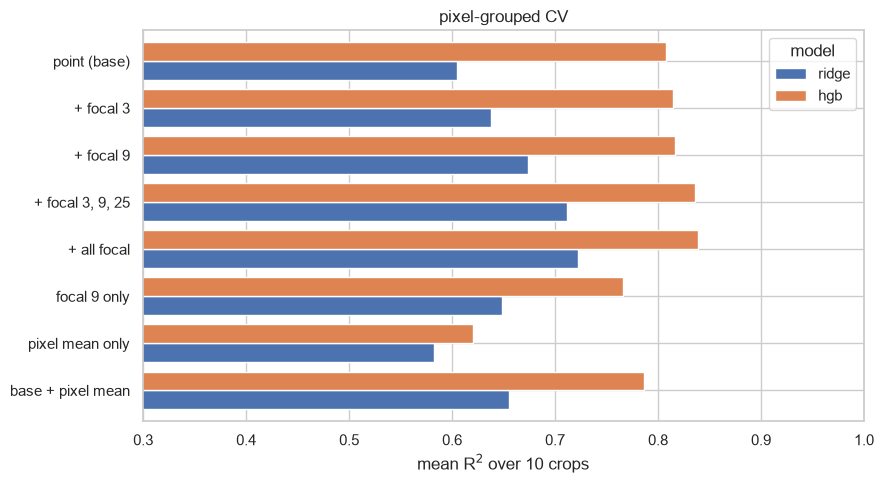

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
tbl["pixel"][MODELS].iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set(title="pixel-grouped CV", xlabel="mean R$^2$ over 10 crops", ylabel="", xlim=(0.3, 1))
plt.tight_layout()
E.save_fig(fig, "m04_context")
plt.show()

## 2. Which neighbourhood scale helps most?
The target is a 1 km value, so wide windows only help if suitability depends on the wider landscape (or if they stand
in for something the 14 drivers miss).

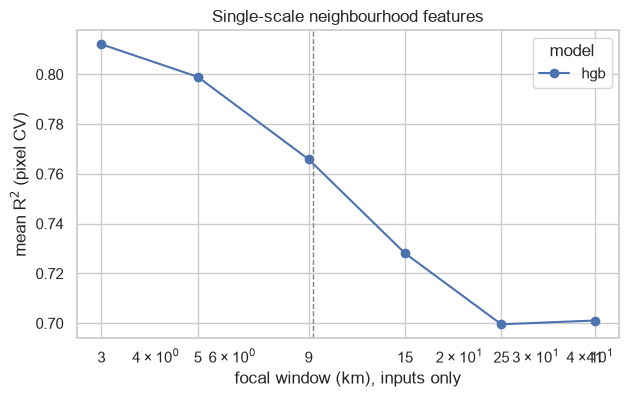

model,hgb
window (km),
3,0.812
5,0.799
9,0.766
15,0.728
25,0.700
41,0.701


In [6]:
scales = {}
for k in SIZES:
    r, _ = E.run_grid(dfc, targets, ["hgb"], ["pixel"], columns=focal(k), n_repeats=2, verbose=False)
    scales[k] = r.groupby("model")["r2"].mean()
scales = pd.DataFrame(scales).T
scales.index.name = "window (km)"
E.save_table(scales.round(4), "m04_focal_scale", index=True)
fig, ax = plt.subplots(figsize=(7, 4))
scales.plot(ax=ax, marker="o")
ax.axvline(9.2, color="grey", ls="--", lw=1)
ax.set(xscale="log", xlabel="focal window (km), inputs only", ylabel="mean R$^2$ (pixel CV)", title="Single-scale neighbourhood features")
ax.set_xticks(list(SIZES), [str(s) for s in SIZES])
E.save_fig(fig, "m04_focal_scale")
plt.show()
scales.round(3)

## 3. Train on ~9 km pixel averages (one row per GAEZ 5 arc-minute pixel)
Inputs and the 1 km target are averaged over each pixel; the cell-level models are scored on the same pixel averages.

In [7]:
pix = dfc.groupby("pix").agg(pix_row=("pix_row", "first"), pix_col=("pix_col", "first"), n_cells=("grid_id", "size"),
                             **{c: (c, "mean") for c in base}, **{E.target_col(c): (E.target_col(c), "mean") for c in E.CROPS})
pix = pix.reset_index()
pix["row"] = pix["pix_row"] - pix["pix_row"].min()
pix["col"] = pix["pix_col"] - pix["pix_col"].min()
print(pix.shape, "pixels; cells per pixel: min", pix.n_cells.min(), "median", int(pix.n_cells.median()), "max", pix.n_cells.max())

ptargets = {c: pix[E.target_col(c)].to_numpy() for c in E.CROPS}
PMODELS = ["ridge", "knn", "et", "hgb"]
pres, _ = E.run_grid(pix, ptargets, PMODELS, ["random", "block2", "block3"], columns=base, n_repeats=5, verbose=False)
E.save_table(pres, "m04_pixel_level_raw")
ptab = pres.groupby(["model", "scheme"])["r2"].mean().unstack("scheme")[["random", "block2", "block3"]]
ptab.round(3)

(163, 30) pixels; cells per pixel: min 1 median 77 max 100


scheme,random,block2,block3
model,,,
et,0.609,0.552,0.528
hgb,0.503,0.418,0.391
knn,0.483,0.437,0.406
ridge,0.520,0.459,0.469


In [8]:
# Cell-level models, predictions averaged back to pixels, scored with equal weight per pixel (same footing as above).
from sklearn.metrics import r2_score
pix_truth = {c: df.groupby("pix")[E.target_col(c)].mean() for c in E.CROPS}
rows = []
for fset in ["point (base)", "+ focal 9", "+ all focal"]:
    for (m, c, s, r), pred in keep[fset].items():
        if s != "pixel":
            continue
        agg = pd.Series(pred).groupby(df["pix"].to_numpy()).mean()
        rows.append({"feature_set": fset, "model": m, "crop": c, "repeat": r, "r2_pixel_level": r2_score(pix_truth[c].loc[agg.index], agg)})
agg_df = pd.DataFrame(rows)
cell_vs_pix = agg_df.groupby(["feature_set", "model"])["r2_pixel_level"].mean().unstack("model")
cell_vs_pix.round(3)

model,hgb,ridge
feature_set,,
+ all focal,0.732,0.642
+ focal 9,0.704,0.574
point (base),0.669,0.504


In [9]:
ptab_best = ptab.max(axis=1).sort_values(ascending=False)
print(f"Pixel-level training ({len(pix)} rows), best CV scheme per model - mean R2 over crops:")
print(pd.concat([ptab, ptab_best.rename("best")], axis=1).round(3).to_string())
print()
print("Cell-level training, scored at pixel level (pixel CV):")
print(cell_vs_pix.round(3).to_string())

Pixel-level training (163 rows), best CV scheme per model - mean R2 over crops:
       random  block2  block3   best
model                               
et      0.609   0.552   0.528  0.609
hgb     0.503   0.418   0.391  0.503
knn     0.483   0.437   0.406  0.483
ridge   0.520   0.459   0.469  0.520

Cell-level training, scored at pixel level (pixel CV):
model           hgb  ridge
feature_set               
+ all focal   0.732  0.642
+ focal 9     0.704  0.574
point (base)  0.669  0.504
